# 따릉이 일별 대여 수요 분석: 2차 데이터 EDA

## 분석 범위
서울시 공공자전거 일별 대여량과 ASOS 서울(108) 기상자료를 2023~2025년 기준으로 결합한다. AWS 서대문(412)은 ASOS 강수량 공란을 살펴보는 보조 비교 자료로만 사용한다.

## 분석 원칙
- 원본 파일을 수정하지 않는다. ASOS 강수량 공란은 원본 그대로 보존한다.
- AWS와 날짜가 겹치는 ASOS 공란의 AWS 관측값을 비교하되, AWS 값을 ASOS 대체값으로 사용하지 않는다.
- 강수량 공란을 0으로 둔 결과는 민감도 분석으로만 제시한다.
- 공휴일·강수량·낮은 대여량의 동시 발생은 관찰 결과이며, 원인이나 인과관계로 단정하지 않는다.
- 매우 낮은 대여량도 근거 없이 삭제하지 않고 점검 대상으로 남긴다.

이 노트북은 중간 보고서의 데이터 구성, 품질 점검, 탐색 결과와 한계를 재현하기 위한 작업 기록이다.

## 데이터 출처와 변수 정의

| 자료 | 출처·지점 | 원자료 열 | 기간·단위 | 분석에서의 역할 및 주의점 |
|---|---|---|---|---|
| 따릉이 일별 대여건수 | 서울 열린데이터광장, 서울시 제공 | 대여일자(2023년 상반기는 대여일시), 대여건수 | 2023-01-01~2025-12-31, 일별 건수 | 서울시 전체 일별 대여 집계. 대여소별 공급·재배치 및 개별 대여 기록은 포함하지 않음 |
| ASOS 일자료 | 기상청 기상자료개방포털, 서울 108 | 평균기온(°C), 최저기온(°C), 최고기온(°C), 일강수량(mm) | 2023-01-01~2025-12-31, 일 단위 | 주 분석 기상자료. 기상청은 겨울철 강수 관측이 3시간 간격이라고 안내하지만, 이 사실만으로 일강수량 공란을 0으로 해석하지 않음 |
| AWS 일자료 | 기상청 기상자료개방포털, 서대문 412 | 일강수량(mm) | 파일 범위 2023-01-01~2025-12-31, 1,091일 수록 | ASOS 공란과 공간적으로 비교하는 보조 자료. ASOS 대체값으로 사용하지 않음 |
| 달력 파생 변수 | 날짜에서 생성 | 연도, 월, 요일, 주말, 공휴일 | 날짜별 | 계절·요일·공휴일별 탐색 및 통제에 사용 |

서울시 데이터셋 설명은 따릉이의 기간별·대여소별 대여·반납 현황을 제공한다고 되어 있다. 이번 분석 파일은 그중 일별 대여건수 집계 파일을 선택했다. 원자료 파일은 2023~2025년 반기별 6개이며, 같은 2025년 하반기 파일이 두 번 제공되어 파일 내용의 완전 일치를 확인한 뒤 하나만 사용했다.

출처: [서울시 공공자전거 따릉이 이용현황](https://data.seoul.go.kr/dataList/OA-14994/F/1/datasetView.do), [기상청 ASOS 자료](https://data.kma.go.kr/data/grnd/selectAsosRltmList.do?pgmNo=36), [기상청 AWS 자료](https://data.kma.go.kr/data/grnd/selectAwsRltmList.do).

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")


## 1. 원자료 불러오기

현재 실행 환경의 업로드 폴더와 저장소 안의 data/raw 폴더를 차례로 찾는다. 다른 위치에 원자료를 둔 경우 DATA_DIR을 직접 지정하면 된다.

In [9]:
RENTAL_FILES = [
    "서울특별시 공공자전거 일별 대여건수_23.1-6.xlsx",
    "서울특별시 공공자전거 일별 대여건수_23.7-12.csv",
    "서울특별시 공공자전거 일별 대여건수_24.1-6.csv",
    "서울특별시 공공자전거 일별 대여건수_24.7-12.csv",
    "서울특별시 공공자전거 일별 대여건수_25.1-6.csv",
    "서울특별시 공공자전거 일별 대여건수_25.7-12.csv",
]
ASOS_FILE = "OBS_ASOS_DD_20261123230640.csv"
AWS_FILE = "OBS_AWS_DD_20261123234148.csv"

from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\ojh23\Documents\projects\llm-data-analysis-study\data-analysis-project\data\raw"
)

missing = [name for name in RENTAL_FILES if not (DATA_DIR / name).exists()]
if missing:
    print("찾지 못한 파일:")
    for name in missing:
        print("-", name)
    raise FileNotFoundError("위 파일을 DATA_DIR 폴더에 넣거나 파일명을 확인하세요.")

print("원자료 폴더:", DATA_DIR)

def read_csv_flexible(path):
    for encoding in ("cp949", "utf-8-sig", "utf-8"):
        try:
            return pd.read_csv(path, encoding=encoding)
        except UnicodeDecodeError:
            continue
    raise UnicodeError(f"인코딩을 판별할 수 없습니다: {path}")

rental_parts = []
for filename in RENTAL_FILES:
    path = DATA_DIR / filename
    frame = pd.read_excel(path) if path.suffix.lower() == ".xlsx" else read_csv_flexible(path)
    date_col = "대여일시" if "대여일시" in frame.columns else "대여일자"
    part = frame[[date_col, "대여건수"]].rename(columns={date_col: "date", "대여건수": "rentals"})
    part["source_file"] = filename
    rental_parts.append(part)

rentals = pd.concat(rental_parts, ignore_index=True)
rentals["date"] = pd.to_datetime(rentals["date"], errors="coerce")
rentals["rentals"] = pd.to_numeric(rentals["rentals"], errors="coerce")

asos = read_csv_flexible(DATA_DIR / ASOS_FILE)
asos["date"] = pd.to_datetime(asos["일시"], errors="coerce")
asos = asos[["date", "지점", "지점명", "평균기온(°C)", "일강수량(mm)"]].rename(
    columns={"평균기온(°C)": "temp_c", "일강수량(mm)": "rain_asos_mm"}
)
asos["temp_c"] = pd.to_numeric(asos["temp_c"], errors="coerce")
asos["rain_asos_mm"] = pd.to_numeric(asos["rain_asos_mm"], errors="coerce")

aws = read_csv_flexible(DATA_DIR / AWS_FILE)
aws["date"] = pd.to_datetime(aws["일시"], errors="coerce")
aws = aws[["date", "지점", "지점명", "일강수량(mm)"]].rename(columns={"일강수량(mm)": "rain_aws412_mm"})
aws["rain_aws412_mm"] = pd.to_numeric(aws["rain_aws412_mm"], errors="coerce")

print("따릉이:", rentals.shape, "ASOS:", asos.shape, "AWS:", aws.shape)


원자료 폴더: C:\Users\ojh23\Documents\projects\llm-data-analysis-study\data-analysis-project\data\raw
따릉이: (1096, 3) ASOS: (1096, 5) AWS: (1091, 4)


## 2. 원자료 품질 점검

자료 행 수만 확인하지 않고 날짜 범위, 중복, 결측, 값의 범위와 예상 날짜 누락을 확인한다.

In [10]:
expected_dates = pd.date_range("2023-01-01", "2025-12-31", freq="D")
expected_set = set(expected_dates)

rental_check = pd.DataFrame([
    {"file": f, "rows": len(g), "date_min": g.date.min(), "date_max": g.date.max(),
     "null_date": int(g.date.isna().sum()), "null_rentals": int(g.rentals.isna().sum()),
     "duplicate_dates": int(g.date.duplicated().sum()), "negative_rentals": int(g.rentals.lt(0).sum()),
     "zero_rental_days": int(g.rentals.eq(0).sum())}
    for f, g in rentals.groupby("source_file", sort=False)
])
print("파일별 대여 자료 점검")
print(rental_check.to_string(index=False))

rental_dates = set(rentals.date.dropna())
print("\n대여자료 전체 행/고유 날짜:", len(rentals), rentals.date.nunique())
print("예상 3년 날짜 수:", len(expected_dates), "누락 날짜:", len(expected_set - rental_dates))
print("중복 날짜:", int(rentals.date.duplicated().sum()))
print("날짜별 대여량이 정수인지:", bool((rentals.rentals.dropna() % 1 == 0).all()))

for label, frame in [("ASOS 108", asos), ("AWS 412", aws)]:
    unique = frame.date.dropna()
    gaps = expected_set - set(unique)
    print(f"{label}: rows={len(frame)}, date_range={unique.min().date()}~{unique.max().date()}, "
          f"duplicate_dates={int(unique.duplicated().sum())}, missing_3yr_dates={len(gaps)}, "
          f"rain_null={int(frame.iloc[:, -1].isna().sum())}")
    if label == "AWS 412":
        print("AWS 누락 날짜:", [d.strftime("%Y-%m-%d") for d in sorted(gaps)])


파일별 대여 자료 점검
                           file  rows   date_min   date_max  null_date  null_rentals  duplicate_dates  negative_rentals  zero_rental_days
서울특별시 공공자전거 일별 대여건수_23.1-6.xlsx   181 2023-01-01 2023-06-30          0             0                0                 0                 0
서울특별시 공공자전거 일별 대여건수_23.7-12.csv   184 2023-07-01 2023-12-31          0             0                0                 0                 0
 서울특별시 공공자전거 일별 대여건수_24.1-6.csv   182 2024-01-01 2024-06-30          0             0                0                 0                 0
서울특별시 공공자전거 일별 대여건수_24.7-12.csv   184 2024-07-01 2024-12-31          0             0                0                 0                 0
 서울특별시 공공자전거 일별 대여건수_25.1-6.csv   181 2025-01-01 2025-06-30          0             0                0                 0                 0
서울특별시 공공자전거 일별 대여건수_25.7-12.csv   184 2025-07-01 2025-12-31          0             0                0                 0                 0

대여자료 전체 행/고유 날짜: 109

In [11]:
# Check the two uploaded copies of the 2025 second-half rental file before using one.
alt_path = DATA_DIR / "서울특별시 공공자전거 일별 대여건수_25.7-12.csv"
selected_name = "서울특별시 공공자전거 일별 대여건수_25.7-12(1).csv"
if alt_path.exists():
    alt = read_csv_flexible(alt_path)
    selected = rentals[rentals.source_file.eq(selected_name)][["date", "rentals"]].sort_values("date").reset_index(drop=True)
    alt_date = "대여일자" if "대여일자" in alt.columns else "대여일시"
    alt = alt[[alt_date, "대여건수"]].rename(columns={alt_date: "date", "대여건수": "rentals"})
    alt["date"] = pd.to_datetime(alt["date"], errors="coerce")
    alt["rentals"] = pd.to_numeric(alt["rentals"], errors="coerce")
    alt = alt.sort_values("date").reset_index(drop=True)
    print("2025 H2 two source copies exactly match:", selected.equals(alt))
    print("Rows in each copy:", len(selected), len(alt), "unique dates:", alt.date.nunique())
else:
    print("Alternate 2025 H2 copy is not in DATA_DIR; no duplicate-version comparison performed.")


2025 H2 two source copies exactly match: False
Rows in each copy: 0 184 unique dates: 184


## 3. 날짜 기준 결합과 키 검증

따릉이 일자료와 ASOS 일자료를 날짜로 1:1 결합한다. AWS는 별도 보조 열로 왼쪽 결합하고, 대여량 행 수가 늘거나 줄지 않았는지 확인한다.

In [12]:
daily = rentals.drop(columns="source_file").merge(
    asos, on="date", how="outer", validate="one_to_one", indicator="rental_asos_merge"
)
daily = daily.merge(
    aws[["date", "rain_aws412_mm"]], on="date", how="left", validate="one_to_one"
).sort_values("date").reset_index(drop=True)
daily["year"] = daily.date.dt.year
daily["month"] = daily.date.dt.month
daily["year_month"] = daily.date.dt.strftime("%Y-%m")
daily["weekday_num"] = daily.date.dt.dayofweek
daily["weekday"] = daily.date.dt.day_name()
daily["weekend"] = daily.weekday_num.ge(5)
daily["log_rentals"] = np.log(daily.rentals)
daily["time_idx"] = np.arange(len(daily))

print("결합 행 수:", len(daily), "고유 날짜:", daily.date.nunique())
print("대여량 결측:", int(daily.rentals.isna().sum()), "기온 결측:", int(daily.temp_c.isna().sum()))
print("ASOS 강수량 공란:", int(daily.rain_asos_mm.isna().sum()), "AWS 날짜 미수록:", int(daily.rain_aws412_mm.isna().sum()))
print("대여자료와 ASOS 양쪽에 있는 날짜:")
print(daily.rental_asos_merge.value_counts().to_string())


결합 행 수: 1096 고유 날짜: 1096
대여량 결측: 0 기온 결측: 0
ASOS 강수량 공란: 628 AWS 날짜 미수록: 5
대여자료와 ASOS 양쪽에 있는 날짜:
rental_asos_merge
both          1096
left_only        0
right_only       0


## 4. 연도·월·요일별 대여량

연도별 수준 변화와 계절·요일 패턴을 시각화한다. 관찰된 변화는 원인을 설명하지 않으므로 해석에 유의한다.

연도별 요약
      days  total_rentals  mean_rentals  median_rentals  min_rentals  max_rentals
year                                                                             
2023   365       44905293      123028.2        131981.0         4992       211000
2024   366       43849586      119807.6        123841.5         9619       194258
2025   365       37373092      102392.0        108852.0        10493       176011


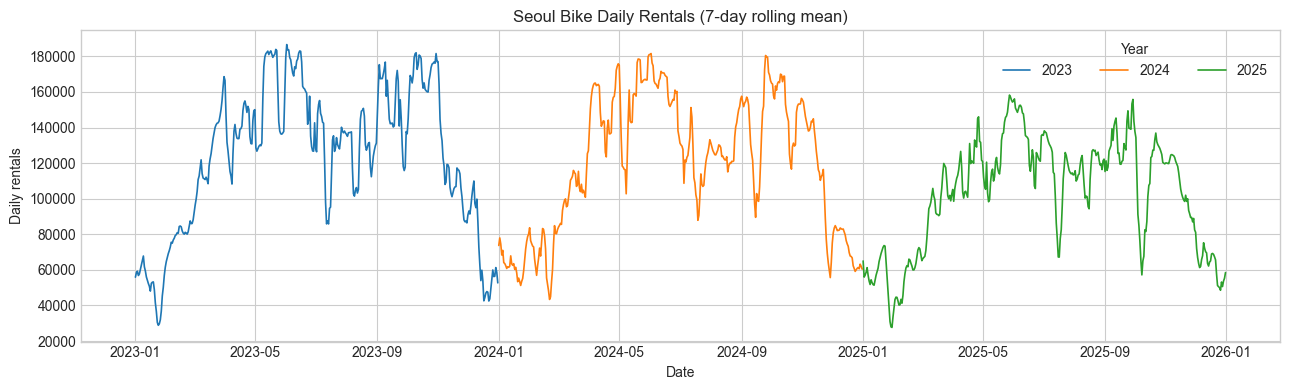

In [13]:
annual = daily.groupby("year").agg(
    days=("rentals", "size"), total_rentals=("rentals", "sum"),
    mean_rentals=("rentals", "mean"), median_rentals=("rentals", "median"),
    min_rentals=("rentals", "min"), max_rentals=("rentals", "max")
).round(1)
print("연도별 요약")
print(annual.to_string())

fig, ax = plt.subplots(figsize=(13, 4))
for year, group in daily.groupby("year"):
    ax.plot(group.date, group.rentals.rolling(7, center=True, min_periods=1).mean(), label=str(year), linewidth=1.2)
ax.set(title="Seoul Bike Daily Rentals (7-day rolling mean)", xlabel="Date", ylabel="Daily rentals")
ax.legend(title="Year", ncol=3)
fig.tight_layout()
display(fig)
plt.close(fig)


월별 평균 대여량
year       2023      2024      2025
month                              
1       50692.0   63979.0   54979.0
2       79697.0   70059.0   58198.0
3      125340.0  101653.0   92805.0
4      136070.0  153330.0  121027.0
5      159771.0  154485.0  124496.0
6      164454.0  161932.0  134144.0
7      126839.0  120104.0  114071.0
8      126951.0  128979.0  114815.0
9      151636.0  141692.0  133078.0
10     170750.0  151186.0  109929.0
11     114465.0  116640.0  106233.0
12      67886.0   73487.0   63393.0

요일별 평균 대여량
year           2023      2024      2025
weekday                                
Monday     131086.0  124005.0  106771.0
Tuesday    130345.0  122844.0  110918.0
Wednesday  132759.0  127410.0  110987.0
Thursday   129593.0  129235.0  114744.0
Friday     133380.0  133519.0  104897.0
Saturday   106939.0  104503.0   82937.0
Sunday      97585.0   96997.0   85326.0


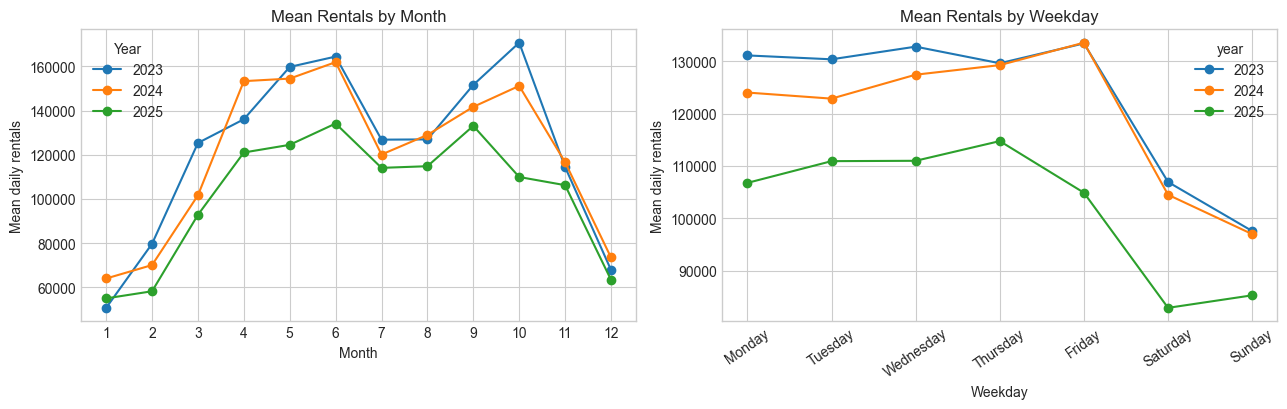

In [14]:
monthly = daily.groupby(["year", "month"], as_index=False).rentals.mean()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = daily.groupby(["year", "weekday"]).rentals.mean().unstack("year").reindex(weekday_order)
print("월별 평균 대여량")
print(monthly.pivot(index="month", columns="year", values="rentals").round(0).to_string())
print("\n요일별 평균 대여량")
print(weekday_summary.round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for year, group in monthly.groupby("year"):
    axes[0].plot(group.month, group.rentals, marker="o", label=str(year))
axes[0].set(title="Mean Rentals by Month", xlabel="Month", ylabel="Mean daily rentals", xticks=range(1, 13))
axes[0].legend(title="Year")
weekday_summary.plot(marker="o", ax=axes[1])
axes[1].set(title="Mean Rentals by Weekday", xlabel="Weekday", ylabel="Mean daily rentals")
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
display(fig)
plt.close(fig)


## 5. 강수량 공란과 AWS 412 대조

ASOS 강수량의 공란과 숫자 0은 구분한다. AWS와 비교할 때에도 실제 강수량 대체값으로 사용하지 않는다.

연도별 강수자료 상태
      days  asos_blank_days  asos_numeric_days  aws_available_days
year                                                              
2023   365              217                148                 365
2024   366              206                160                 365
2025   365              205                160                 361

ASOS 공란-AWS 교차점검
ASOS blank with AWS date       625
among them AWS zero            625
among them AWS positive          0
ASOS blank with no AWS date      3

두 지점 강수량 숫자 비교: n= 466 상관계수= 0.977 평균 절대 차이(mm)= 1.45

월별 ASOS 강수량 공란 비율(%)
month
1     55.9
2     72.9
3     68.8
4     64.4
5     62.4
6     51.1
7     34.4
8     43.0
9     52.2
10    59.1
11    66.7
12    58.1


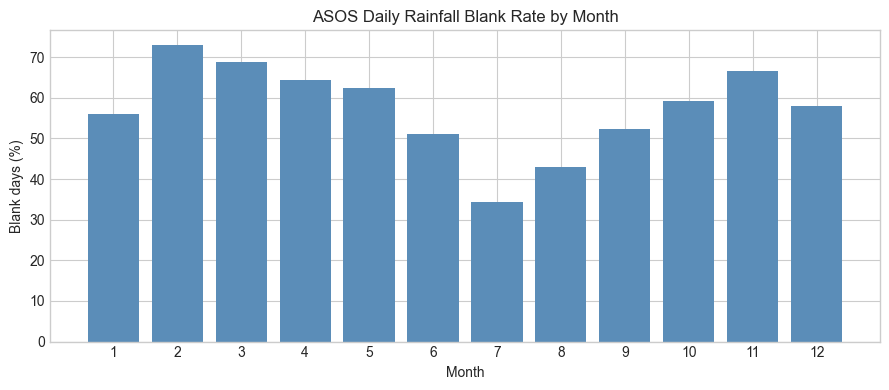

In [15]:
rain_status = daily.assign(
    asos_rain_blank=daily.rain_asos_mm.isna(),
    aws_date_available=daily.rain_aws412_mm.notna()
).groupby("year").agg(
    days=("date", "size"), asos_blank_days=("asos_rain_blank", "sum"),
    asos_numeric_days=("rain_asos_mm", "count"), aws_available_days=("aws_date_available", "sum")
)
print("연도별 강수자료 상태")
print(rain_status.to_string())

blank_overlap = daily[daily.rain_asos_mm.isna() & daily.rain_aws412_mm.notna()]
blank_compare = {
    "ASOS blank with AWS date": len(blank_overlap),
    "among them AWS zero": int(blank_overlap.rain_aws412_mm.eq(0).sum()),
    "among them AWS positive": int(blank_overlap.rain_aws412_mm.gt(0).sum()),
    "ASOS blank with no AWS date": int((daily.rain_asos_mm.isna() & daily.rain_aws412_mm.isna()).sum()),
}
print("\nASOS 공란-AWS 교차점검")
print(pd.Series(blank_compare).to_string())

numeric_pair = daily.dropna(subset=["rain_asos_mm", "rain_aws412_mm"])
print("\n두 지점 강수량 숫자 비교: n=", len(numeric_pair),
      "상관계수=", round(numeric_pair.rain_asos_mm.corr(numeric_pair.rain_aws412_mm), 3),
      "평균 절대 차이(mm)=", round((numeric_pair.rain_asos_mm - numeric_pair.rain_aws412_mm).abs().mean(), 2))

fig, ax = plt.subplots(figsize=(9, 4))
monthly_missing = daily.groupby("month").rain_asos_mm.apply(lambda x: x.isna().mean() * 100)
print("\n월별 ASOS 강수량 공란 비율(%)")
print(monthly_missing.round(1).to_string())
ax.bar(monthly_missing.index, monthly_missing.values, color="#5b8db8")
ax.set(title="ASOS Daily Rainfall Blank Rate by Month", xlabel="Month", ylabel="Blank days (%)", xticks=range(1, 13))
fig.tight_layout()
display(fig)
plt.close(fig)


## 6. 강수량 처리 민감도

아래 회귀는 탐색용이다. 종속변수는 로그 대여량이며, 연·월과 요일 고정효과, 평균기온을 통제한다. 일별 오차의 연속성을 고려해 Newey–West 방식(최대 7일 시차)의 표준오차를 계산한다. 결과는 인과효과가 아니다.

ASOS 공란을 0으로 둔 경우는 실제 데이터 수정이 아니라 민감도 비교를 위한 가정이다.

In [16]:
def fit_hac_calendar(frame, feature_cols, full_length, max_lag=7):
    """Log rentals OLS with year-month and weekday fixed effects; HAC covariance on daily index."""
    g = frame.dropna(subset=feature_cols + ["temp_c", "log_rentals"]).copy()
    fixed = pd.get_dummies(g[["year_month", "weekday"]].astype(str), drop_first=True, dtype=float)
    Xdf = pd.concat([
        pd.Series(1.0, index=g.index, name="intercept"),
        g[feature_cols + ["temp_c"]].astype(float), fixed
    ], axis=1)
    X = Xdf.to_numpy(dtype=float)
    y = g.log_rentals.to_numpy(dtype=float)
    n, k = X.shape
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    residual = y - X @ beta
    bread = np.linalg.pinv(X.T @ X)
    scores = np.zeros((full_length, k))
    scores[g.time_idx.to_numpy(dtype=int)] = X * residual[:, None]
    meat = scores.T @ scores
    for lag in range(1, max_lag + 1):
        weight = 1 - lag / (max_lag + 1)
        cross = scores[lag:].T @ scores[:-lag]
        meat += weight * (cross + cross.T)
    covariance = bread @ meat @ bread * (n / max(n - k, 1))
    rows = []
    for feature in feature_cols:
        j = list(Xdf.columns).index(feature)
        se = float(np.sqrt(max(covariance[j, j], 0)))
        lo, hi = beta[j] - 1.96 * se, beta[j] + 1.96 * se
        rows.append({
            "feature": feature, "n": n, "coef_log": beta[j],
            "effect_pct": 100 * (np.exp(beta[j]) - 1),
            "ci95_low_pct": 100 * (np.exp(lo) - 1),
            "ci95_high_pct": 100 * (np.exp(hi) - 1)
        })
    return pd.DataFrame(rows)

scenarios = []
observed = daily.dropna(subset=["rain_asos_mm"]).copy()
observed["rain_day"] = observed.rain_asos_mm.gt(0).astype(int)
scenarios.append(("ASOS observed only", observed, ["rain_day"]))
assume_zero = daily.copy()
assume_zero["rain_asos_sensitivity_mm"] = assume_zero.rain_asos_mm.fillna(0)
assume_zero["rain_day"] = assume_zero.rain_asos_sensitivity_mm.gt(0).astype(int)
scenarios.append(("ASOS blank assumed zero (sensitivity only)", assume_zero, ["rain_day"]))
aws_alt = daily.dropna(subset=["rain_aws412_mm"]).copy()
aws_alt["rain_day"] = aws_alt.rain_aws412_mm.gt(0).astype(int)
scenarios.append(("AWS 412 alternate indicator", aws_alt, ["rain_day"]))

sensitivity_results = []
for label, frame, features in scenarios:
    result = fit_hac_calendar(frame, features, len(daily))
    result.insert(0, "scenario", label)
    sensitivity_results.append(result)
sensitivity = pd.concat(sensitivity_results, ignore_index=True)
print(sensitivity.round(3).to_string(index=False))

# Compare rainfall amount as a separate sensitivity; the ASOS raw column remains unchanged.
amount_scenarios = []
for label, frame, rain_col in [
    ("ASOS observed amount", daily, "rain_asos_mm"),
    ("ASOS amount with blank=0 assumption", daily.assign(rain_asos_sensitivity_mm=daily.rain_asos_mm.fillna(0)), "rain_asos_sensitivity_mm"),
    ("AWS 412 amount", daily, "rain_aws412_mm"),
]:
    result = fit_hac_calendar(frame, [rain_col], len(daily))
    result.insert(0, "scenario", label)
    amount_scenarios.append(result)
amount_sensitivity = pd.concat(amount_scenarios, ignore_index=True)
print("\n강수량 1mm 증가와 연관된 로그 대여량 변화율(선형 탐색 가정)")
print(amount_sensitivity[["scenario", "n", "effect_pct", "ci95_low_pct", "ci95_high_pct"]].round(3).to_string(index=False))


                                  scenario  feature    n  coef_log  effect_pct  ci95_low_pct  ci95_high_pct
                        ASOS observed only rain_day  468    -0.458     -36.719       -41.462        -31.592
ASOS blank assumed zero (sensitivity only) rain_day 1096    -0.513     -40.119       -44.035        -35.930
               AWS 412 alternate indicator rain_day 1091    -0.576     -43.787       -47.809        -39.455

강수량 1mm 증가와 연관된 로그 대여량 변화율(선형 탐색 가정)
                           scenario    n  effect_pct  ci95_low_pct  ci95_high_pct
               ASOS observed amount  468      -1.955        -2.421         -1.486
ASOS amount with blank=0 assumption 1096      -2.141        -2.636         -1.644
                     AWS 412 amount 1091      -2.189        -2.678         -1.699


## 7. 공휴일과 대여량

공휴일 플래그에는 정기 공휴일·대체공휴일뿐 아니라 임시공휴일과 선거일도 포함한다. 해당 연도 자료에 맞춘 날짜 목록이며, 공식 월력요항과 정부 공고를 참고했다.

In [17]:
holiday_dates = set()
def add_holiday(start, end=None):
    holiday_dates.update(pd.date_range(start, end or start))

# 2023: annual calendar, substitute holiday, and temporary holiday
for date in ["2023-01-01", "2023-03-01", "2023-05-05", "2023-05-27", "2023-05-29",
             "2023-06-06", "2023-08-15", "2023-10-02", "2023-10-03", "2023-10-09", "2023-12-25"]:
    add_holiday(date)
add_holiday("2023-01-21", "2023-01-24")
add_holiday("2023-09-28", "2023-09-30")
# 2024: includes election day and temporary Armed Forces Day holiday
for date in ["2024-01-01", "2024-03-01", "2024-04-10", "2024-05-05", "2024-05-06", "2024-05-15",
             "2024-06-06", "2024-08-15", "2024-10-01", "2024-10-03", "2024-10-09", "2024-12-25"]:
    add_holiday(date)
add_holiday("2024-02-09", "2024-02-12")
add_holiday("2024-09-16", "2024-09-18")
# 2025: includes temporary holiday and presidential election day
for date in ["2025-01-01", "2025-01-27", "2025-03-01", "2025-03-03", "2025-05-05", "2025-05-06",
             "2025-06-03", "2025-06-06", "2025-08-15", "2025-10-03", "2025-10-08", "2025-10-09", "2025-12-25"]:
    add_holiday(date)
add_holiday("2025-01-28", "2025-01-30")
add_holiday("2025-10-05", "2025-10-07")

daily["public_holiday"] = daily.date.isin(holiday_dates)
daily["weekday_holiday"] = daily.public_holiday & daily.weekday_num.lt(5)
daily["day_type"] = np.select(
    [daily.weekday_holiday, daily.weekend & ~daily.public_holiday, daily.weekend & daily.public_holiday],
    ["weekday holiday", "non-holiday weekend", "weekend holiday"], default="ordinary weekday"
)
holiday_summary = daily.groupby("day_type").rentals.agg(["count", "mean", "median"]).round(0)
print("공휴일 플래그 일수:", int(daily.public_holiday.sum()),
      "평일 공휴일:", int(daily.weekday_holiday.sum()))
print(holiday_summary.to_string())

holiday_model = daily.dropna(subset=["rain_aws412_mm"]).copy()
holiday_model["weekday_holiday"] = holiday_model.weekday_holiday.astype(int)
holiday_result = fit_hac_calendar(holiday_model, ["weekday_holiday", "rain_aws412_mm"], len(daily))
print("\n연·월, 요일, 평균기온, AWS 강수량을 통제한 탐색 회귀")
print(holiday_result.round(3).to_string(index=False))


공휴일 플래그 일수: 56 평일 공휴일: 46
                     count      mean    median
day_type                                      
non-holiday weekend    303   97460.0  100000.0
ordinary weekday       737  125130.0  131896.0
weekday holiday         46   85795.0   89119.0
weekend holiday         10   43022.0   36111.0

연·월, 요일, 평균기온, AWS 강수량을 통제한 탐색 회귀
        feature    n  coef_log  effect_pct  ci95_low_pct  ci95_high_pct
weekday_holiday 1091    -0.501     -39.405       -48.054        -29.315
 rain_aws412_mm 1091    -0.022      -2.188        -2.671         -1.704


In [18]:
audit_dates = pd.to_datetime([
    "2023-05-28", "2023-08-10", "2024-02-21", "2024-05-05",
    "2025-06-20", "2025-10-06"
])
source_audit = rentals[rentals.date.isin(audit_dates)][["date", "rentals", "source_file"]].copy()
source_audit = source_audit.merge(
    asos[["date", "temp_c", "rain_asos_mm"]], on="date", how="left", validate="one_to_one"
).merge(aws[["date", "rain_aws412_mm"]], on="date", how="left", validate="one_to_one")
source_audit["public_holiday"] = source_audit.date.isin(holiday_dates)
print("Low-rental candidates checked against the selected source rows")
print(source_audit.to_string(index=False))
print("\nThese records are present in the downloaded source files. The aggregate file alone cannot establish whether a service outage occurred or explain why rentals were low.")


Low-rental candidates checked against the selected source rows
      date  rentals                     source_file  temp_c  rain_asos_mm  rain_aws412_mm  public_holiday
2023-05-28     4992 서울특별시 공공자전거 일별 대여건수_23.1-6.xlsx    19.2          41.8            41.0           False
2023-08-10     9333 서울특별시 공공자전거 일별 대여건수_23.7-12.csv    22.2          86.1            88.0           False
2024-02-21     9619  서울특별시 공공자전거 일별 대여건수_24.1-6.csv     1.9          17.8            16.0           False
2024-05-05    14293  서울특별시 공공자전거 일별 대여건수_24.1-6.csv    17.8          48.3            48.0            True
2025-06-20    13179  서울특별시 공공자전거 일별 대여건수_25.1-6.csv    24.1          51.1            56.0           False
2025-10-06    10493 서울특별시 공공자전거 일별 대여건수_25.7-12.csv    17.6          36.8            35.0            True

These records are present in the downloaded source files. The aggregate file alone cannot establish whether a service outage occurred or explain why rentals were low.


## 8. 낮은 대여량 후보 점검

각 연·월 안에서 같은 요일의 다른 날짜 평균과 비교해 낮은 날을 찾는다. 이는 이상치 판정이나 삭제 기준이 아니라, 원자료·기상·공휴일·운영 정보를 추가로 확인할 후보를 찾기 위한 절차다.

      date  rentals   weekday  public_holiday  temp_c  rain_asos_mm  rain_aws412_mm  same_month_weekday_peer_mean  ratio_to_peer_mean
2023-05-28     4992    Sunday           False    19.2          41.8            41.0                      143084.0                0.03
2023-08-10     9333  Thursday           False    22.2          86.1            88.0                      164750.0                0.06
2024-02-21     9619 Wednesday           False     1.9          17.8            16.0                      105159.0                0.09
2025-10-06    10493    Monday            True    17.6          36.8            35.0                       93443.0                0.11
2025-06-20    13179    Friday           False    24.1          51.1            56.0                      136157.0                0.10
2025-10-10    13940    Friday           False    17.0          49.3            37.5                      124768.0                0.11
2024-05-05    14293    Sunday            True    17.8         

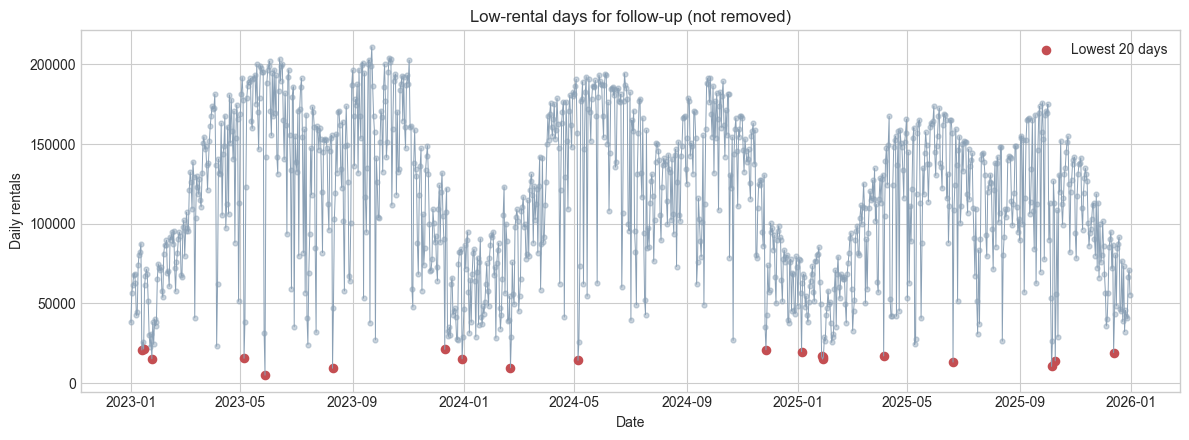

In [19]:
peer = daily.groupby(["year_month", "weekday"]).rentals
count = peer.transform("count")
total = peer.transform("sum")
daily["same_month_weekday_peer_mean"] = (total - daily.rentals) / (count - 1)
daily["ratio_to_peer_mean"] = daily.rentals / daily.same_month_weekday_peer_mean

low_candidates = daily.nsmallest(20, "rentals")[[
    "date", "rentals", "weekday", "public_holiday", "temp_c", "rain_asos_mm", "rain_aws412_mm",
    "same_month_weekday_peer_mean", "ratio_to_peer_mean"
]].copy()
low_candidates["date"] = low_candidates.date.dt.strftime("%Y-%m-%d")
print(low_candidates.round({"temp_c": 1, "rain_asos_mm": 1, "rain_aws412_mm": 1,
                            "same_month_weekday_peer_mean": 0, "ratio_to_peer_mean": 2}).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.date, daily.rentals, linewidth=0.7, color="#8aa0b5")
ax.scatter(daily.date, daily.rentals, s=12, color="#8aa0b5", alpha=0.45)
ax.scatter(pd.to_datetime(low_candidates.date), low_candidates.rentals, s=35, color="#c44e52", label="Lowest 20 days")
ax.set(title="Low-rental days for follow-up (not removed)", xlabel="Date", ylabel="Daily rentals")
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## 9. 연도별 패턴 일관성 점검

3년 자료의 장점을 확인하기 위해 평일·주말 차이와 월별 계절 패턴을 연도별로 비교한다. 월별 지수는 각 연도의 일평균으로 나누어 연도별 대여량 수준 차이를 줄여 계절의 모양을 살핀다. 강수일 회귀는 ASOS 강수량이 숫자로 관측된 날짜만 사용하고, 연·월·요일·평균기온을 통제한 탐색 결과로 제시한다. 강수량 공란은 0으로 바꾸지 않는다. 연도별 표본 수와 신뢰구간을 함께 보고 결과의 불확실성을 해석한다.


In [20]:
# 연도별 결과 일관성 점검: 기술통계와 관측 강수량만 사용한 탐색 회귀
# 1) 평일·주말 평균 격차를 연도별로 비교
weekend = daily.groupby(["year", "weekend"]).rentals.agg(n="count", mean="mean", median="median").reset_index()
weekend["day_type"] = weekend.weekend.map({False: "평일", True: "주말"})
weekend_wide = weekend.pivot(index="year", columns="day_type", values="mean")
weekend_n = weekend.pivot(index="year", columns="day_type", values="n")
weekend_result = pd.DataFrame({
    "평일_일수": weekend_n["평일"], "평일_평균": weekend_wide["평일"],
    "주말_일수": weekend_n["주말"], "주말_평균": weekend_wide["주말"],
})
weekend_result["주말-평일_차이"] = weekend_result["주말_평균"] - weekend_result["평일_평균"]
weekend_result["주말/평일_비율"] = weekend_result["주말_평균"] / weekend_result["평일_평균"]
print("[연도별 평일·주말 대여량]")
print(weekend_result.round(2).to_string())

# 2) 각 연도 평균으로 정규화한 월별 평균: 연도별 전체 수준 차이를 분리해 계절 모양을 비교
monthly_year = daily.groupby(["year", "month"]).rentals.mean().rename("month_mean").reset_index()
annual_mean = daily.groupby("year").rentals.mean().rename("year_mean")
monthly_year = monthly_year.join(annual_mean, on="year")
monthly_year["monthly_index"] = monthly_year.month_mean / monthly_year.year_mean
monthly_index = monthly_year.pivot(index="month", columns="year", values="monthly_index")
print("\n[연도별 평균 대비 월별 대여량 지수: 월평균 / 해당 연도 전체 일평균]")
print(monthly_index.round(2).to_string())

# 3) ASOS 강수량이 숫자로 관측된 날짜만 사용. 공란은 0으로 채우지 않음.
rain_year_results = []
for year, group in daily.groupby("year"):
    observed_year = group.dropna(subset=["rain_asos_mm"]).copy()
    observed_year["rain_day"] = observed_year.rain_asos_mm.gt(0).astype(int)
    fit = fit_hac_calendar(observed_year, ["rain_day"], len(daily))
    row = fit.iloc[0].to_dict()
    row["year"] = year
    row["rainfall_observed_days"] = int(len(observed_year))
    row["blank_rain_days_excluded"] = int(group.rain_asos_mm.isna().sum())
    rain_year_results.append(row)
rain_year = pd.DataFrame(rain_year_results).set_index("year")[[
    "n", "rainfall_observed_days", "blank_rain_days_excluded", "effect_pct", "ci95_low_pct", "ci95_high_pct"
]]
print("\n[연도별 강수일 연관성: ASOS 관측값만 사용, 연·월/요일/평균기온 통제, HAC 7일]")
print(rain_year.round(3).to_string())
print("\n주의: 연도별 추정치는 표본이 작고 관측 강수일 선택 및 모형 가정의 영향을 받는 탐색 결과이며, 인과효과나 예측 성능을 의미하지 않습니다.")


[연도별 평일·주말 대여량]
      평일_일수      평일_평균  주말_일수      주말_평균  주말-평일_차이  주말/평일_비율
year                                                        
2023    260  131432.53    105  102217.48 -29215.05      0.78
2024    262  127372.33    104  100750.35 -26621.98      0.79
2025    261  109668.45    104   84131.03 -25537.42      0.77

[연도별 평균 대비 월별 대여량 지수: 월평균 / 해당 연도 전체 일평균]
year   2023  2024  2025
month                  
1      0.41  0.53  0.54
2      0.65  0.58  0.57
3      1.02  0.85  0.91
4      1.11  1.28  1.18
5      1.30  1.29  1.22
6      1.34  1.35  1.31
7      1.03  1.00  1.11
8      1.03  1.08  1.12
9      1.23  1.18  1.30
10     1.39  1.26  1.07
11     0.93  0.97  1.04
12     0.55  0.61  0.62

[연도별 강수일 연관성: ASOS 관측값만 사용, 연·월/요일/평균기온 통제, HAC 7일]
        n  rainfall_observed_days  blank_rain_days_excluded  effect_pct  ci95_low_pct  ci95_high_pct
year                                                                                                
2023  148                     148            

## 10. 중간 점검 요약 및 남은 일

### 현재 확인된 내용
- 대여 원자료 6개 파일을 날짜 기준으로 결합했고, 2023~2025년 1,096일을 확보했다.
- ASOS 서울 108 강수량은 628일이 공란이다. 원본 공란을 보존한다.
- AWS 서대문 412는 전체 기간 중 1,091일을 제공한다. ASOS 공란과 날짜가 겹치는 날 중 AWS 강수량이 양수인 날은 확인되지 않았으나, AWS는 보조 비교일 뿐 ASOS 대체값이 아니다.
- 평일 평균 대여량은 주말보다 3개 연도 모두 높았고, 월별 지수도 5~6월이 높고 겨울철이 낮은 계절 패턴을 보였다. 연도별 대여량 수준은 달랐으므로 수준과 계절 패턴을 구분해 해석한다.
- ASOS 강수량 관측일만 사용한 연도별 탐색 회귀에서 강수일 계수는 3개 연도 모두 음수였다. 다만 강수량 공란이 연도별 205~217일로 많고 월별 공란 비율도 34.4~72.9%로 차이가 있어, 관측일만 사용한 결과를 전체 날짜로 일반화하지 않는다.
- 낮은 대여량은 근거 없이 제거하지 않는다.

### 최종 단계에서 보완할 내용
- 기상청 자료 설명을 추가 확인해 ASOS 강수량 공란의 의미와 결측 편중을 검토한다. 확인 전에는 강수량 결과를 제한적으로 제시한다.
- 예측을 핵심 목표로 유지할지 결정하고, 유지한다면 시간 순서를 지킨 학습·검증 분할과 단순 기준모형을 적용한다.
- 낮은 대여량 후보일은 서울시 원자료, 기상 상황, 운영 공지와 대조한다.
- 예측 오차 지표와 단순 기준모형을 함께 제시한다.
- 강수량 공란의 의미는 기상청 자료 설명 또는 추가 검증으로 확인하고, 확인되지 않으면 처리 한계로 명시한다.

## 참고한 휴일 자료
- 한국천문연구원 달력자료: https://astro.kasi.re.kr/kor/life/post/calendarData?search_year=2023
- 한국천문연구원 달력자료: https://astro.kasi.re.kr/kor/life/post/calendarData?search_year=2024
- 한국천문연구원 달력자료: https://astro.kasi.re.kr/kor/life/post/calendarData?search_year=2025
- 인사혁신처 2023년 10월 2일 임시공휴일 지정: https://www.mpm.go.kr/mpm/comm/noti/mpmNotice/?boardId=bbs_0000000000000205&category=&cntId=719&mode=view&pageIdx=27
- 인사혁신처 2024년 10월 1일 임시공휴일 지정: https://www.mpm.go.kr/mpm/comm/noti/mpmNotice/?boardId=bbs_0000000000000205&category=&cntId=834&mode=view&pageIdx=20
- 인사혁신처 2025년 1월 27일 임시공휴일 지정: https://www.mpm.go.kr/mpm/comm/noti/mpmNotice/?boardId=bbs_0000000000000205&category=&cntId=904&mode=view&pageIdx=8
- 인사혁신처 2025년 6월 3일 임시공휴일 지정: https://www.mpm.go.kr/mpm/comm/noti/mpmNotice/?boardId=bbs_0000000000000205&category=&cntId=928&mode=view&pageIdx=
